# 01 - Exploration des données / استكشاف البيانات
**Agent 1 - prévision de la demande (LSTM)** · Dataset : Kaggle *Store Sales - Time Series Forecasting* (Favorita).

Objectif : comprendre les données **sans rien supposer**. Les décisions de nettoyage (Étape 4) découlent de ce que l'on observe ici.

In [1]:
import sys
from pathlib import Path

# The notebook lives in notebooks/ -> add the project root so `src` can be imported
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from src.forecast import data_loader as dl

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

config = dl.load_config()
PLOTS = ROOT / config["paths"]["plots_dir"]
PLOTS.mkdir(parents=True, exist_ok=True)
D = config["data"]
DATE, PROD, TARGET, PROMO = D["date_col"], D["product_col"], D["target_col"], D["promo_col"]
print("Project root:", ROOT)

Project root: C:\Users\le\Desktop\dynamic-pricing-ecommerce


## 1. Chargement de `train.csv`

In [2]:
train = dl.load_train(config)
print("Shape:", train.shape)
train.head()

Shape: (3000888, 6)


,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0
1,1,2013-01-01,1,BABY CARE,0.0,0
2,2,2013-01-01,1,BEAUTY,0.0,0
3,3,2013-01-01,1,BEVERAGES,0.0,0
4,4,2013-01-01,1,BOOKS,0.0,0


In [3]:
train.tail()

,id,date,store_nbr,family,sales,onpromotion
3000883,3000883,2017-08-15,9,POULTRY,438.133,0
3000884,3000884,2017-08-15,9,PREPARED FOODS,154.553,1
3000885,3000885,2017-08-15,9,PRODUCE,2419.729,148
3000886,3000886,2017-08-15,9,SCHOOL AND OFFICE SUPPLIES,121.000,8
3000887,3000887,2017-08-15,9,SEAFOOD,16.000,0


In [4]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 3000888 entries, 0 to 3000887
Data columns (total 6 columns):
 #   Column       Dtype         
---  ------       -----         
 0   id           int32         
 1   date         datetime64[us]
 2   store_nbr    int16         
 3   family       category      
 4   sales        float64       
 5   onpromotion  int32         
dtypes: category(1), datetime64[us](1), float64(1), int16(1), int32(2)
memory usage: 77.3 MB


## 2. Valeurs manquantes et doublons / القيم المفقودة والتكرارات

In [5]:
print("Missing values per column:")
print(train.isna().sum())
print("\nFull duplicate rows:", int(train.duplicated().sum()))
print("Panel check:", dl.check_panel_completeness(train, config))

Missing values per column:
id             0
date           0
store_nbr      0
family         0
sales          0
onpromotion    0
dtype: int64

Full duplicate rows: 0
Panel check: {'n_dates': 1684, 'n_stores': 54, 'n_families': 33, 'expected_rows': 3000888, 'actual_rows': 3000888, 'is_complete': True, 'duplicated_keys': 0}


## 3. Statistiques descriptives / إحصاءات وصفية

In [6]:
train[[TARGET, PROMO]].describe().T

,count,mean,std,min,25%,50%,75%,max
sales,3000888.0,357.775749,1101.997721,0.0,0.0,11.0,195.84725,124717.0
onpromotion,3000888.0,2.602770,12.218882,0.0,0.0,0.0,0.00000,741.0


In [7]:
zero_share = (train[TARGET] == 0).mean() * 100
print(f"Share of rows with sales == 0: {zero_share:.1f}%")
print(f"Negative sales: {int((train[TARGET] < 0).sum())}")

Share of rows with sales == 0: 31.3%
Negative sales: 0


## 4. Dates : plage et jours manquants / نطاق التواريخ والأيام الناقصة

In [8]:
print("Date range:", train[DATE].min().date(), "->", train[DATE].max().date())
print("Distinct dates:", train[DATE].nunique())
missing_days = dl.find_missing_dates(train[DATE])
print("Missing calendar days:", [d.date().isoformat() for d in missing_days])

Date range: 2013-01-01 -> 2017-08-15
Distinct dates: 1684
Missing calendar days: ['2013-12-25', '2014-12-25', '2015-12-25', '2016-12-25']


## 5. Distribution des familles de produits / توزيع فئات المنتجات

In [9]:
fam = train.groupby(PROD, observed=True).agg(total_sales=(TARGET, "sum"),
                                              zero_share=(TARGET, lambda s: (s == 0).mean())).sort_values("total_sales", ascending=False)
fam["total_sales"] = fam["total_sales"].round(0)
fam["zero_share"] = (fam["zero_share"] * 100).round(1)
fam

,total_sales,zero_share
family,,
GROCERY I,343462735.0,8.1
BEVERAGES,216954486.0,8.1
PRODUCE,122704685.0,28.4
CLEANING,97521289.0,8.1
DAIRY,64487709.0,8.1
BREAD/BAKERY,42133946.0,8.1
POULTRY,31876004.0,8.1
MEATS,31086468.0,8.1
PERSONAL CARE,24592051.0,8.1


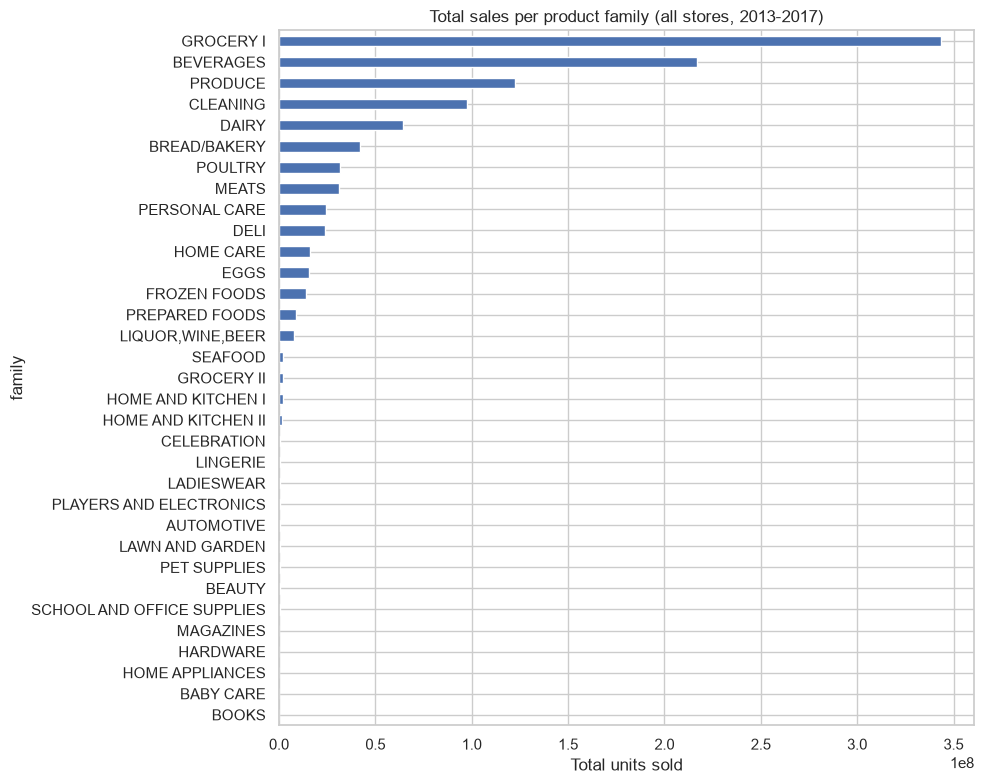

In [10]:
fig, ax = plt.subplots(figsize=(10, 8))
fam["total_sales"].sort_values().plot.barh(ax=ax)
ax.set_title("Total sales per product family (all stores, 2013-2017)")
ax.set_xlabel("Total units sold")
plt.tight_layout()
plt.savefig(PLOTS / "01_sales_per_family.png", dpi=120)
plt.show()

## 6. Ventes totales dans le temps / المبيعات عبر الزمن
On somme les ventes de tous les magasins et de toutes les familles.

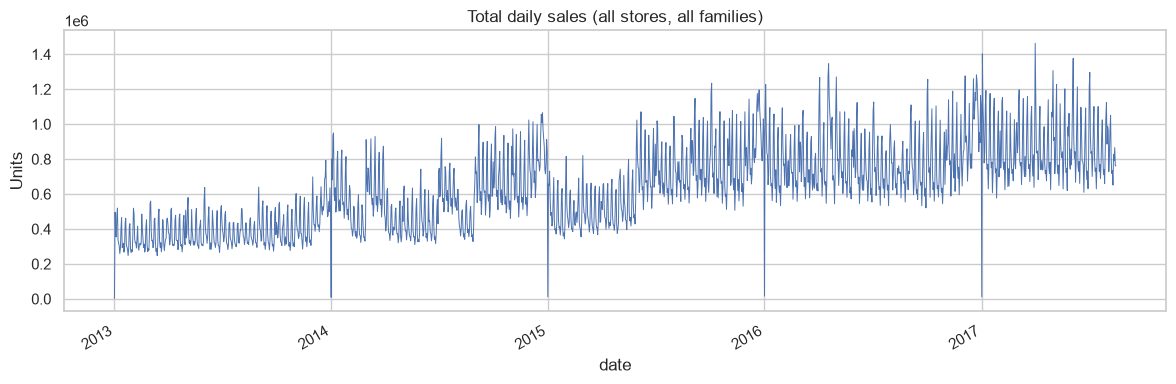

In [11]:
daily = train.groupby(DATE)[TARGET].sum()
fig, ax = plt.subplots(figsize=(12, 4))
daily.plot(ax=ax, linewidth=0.7)
ax.set_title("Total daily sales (all stores, all families)")
ax.set_ylabel("Units")
plt.tight_layout()
plt.savefig(PLOTS / "01_daily_sales.png", dpi=120)
plt.show()

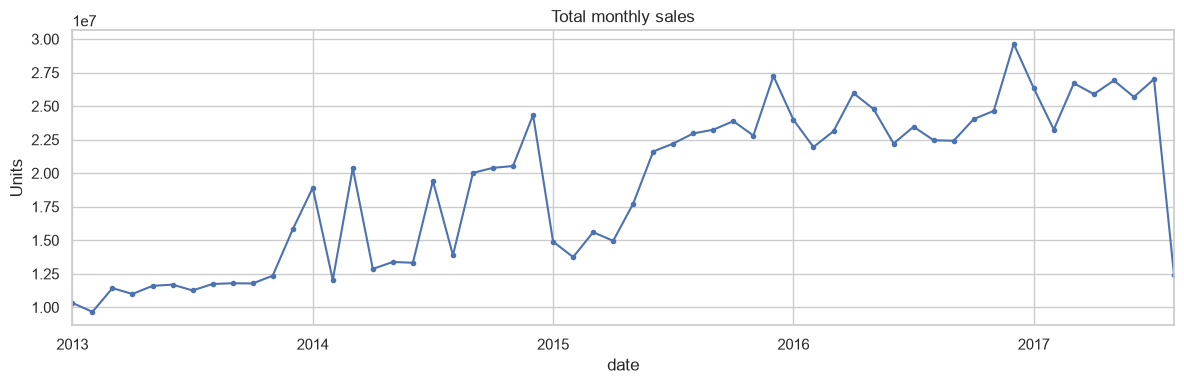

In [12]:
monthly = daily.resample("MS").sum()
fig, ax = plt.subplots(figsize=(12, 4))
monthly.plot(ax=ax, marker="o", markersize=3)
ax.set_title("Total monthly sales")
ax.set_ylabel("Units")
plt.tight_layout()
plt.savefig(PLOTS / "01_monthly_sales.png", dpi=120)
plt.show()

## 7. Saisonnalité (jour de semaine, mois) / الموسمية

C:\Users\le\AppData\Local\Temp\ipykernel_12136\861756070.py:1: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  dow = daily.groupby(daily.index.dayofweek).mean()


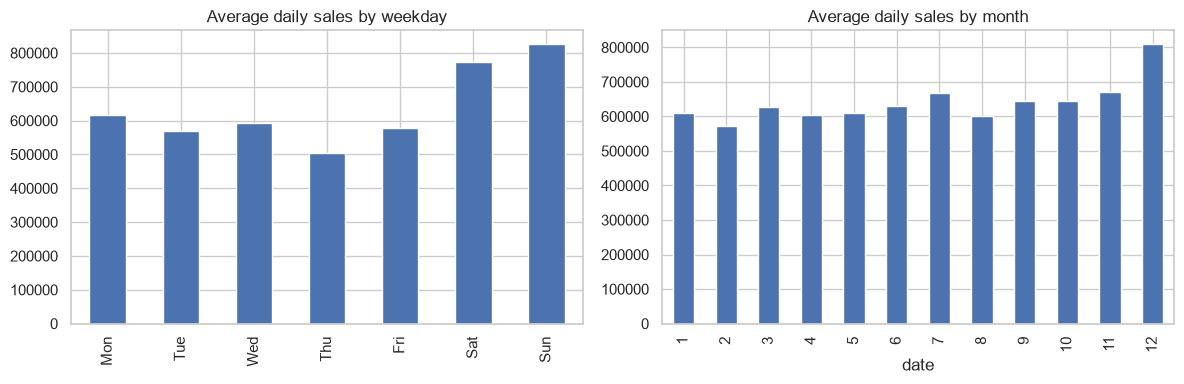

In [13]:
dow = daily.groupby(daily.index.dayofweek).mean()
dow.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
mon = daily.groupby(daily.index.month).mean()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
dow.plot.bar(ax=axes[0], title="Average daily sales by weekday")
mon.plot.bar(ax=axes[1], title="Average daily sales by month")
plt.tight_layout()
plt.savefig(PLOTS / "01_seasonality.png", dpi=120)
plt.show()

## 8. Promotions et ventes / العروض والمبيعات

Rows with onpromotion > 0: 20.4%
Share of rows with a promotion, by year (%):
date
2013     0.0
2014    10.0
2015    20.9
2016    35.1
2017    45.3
Name: onpromotion, dtype: float64


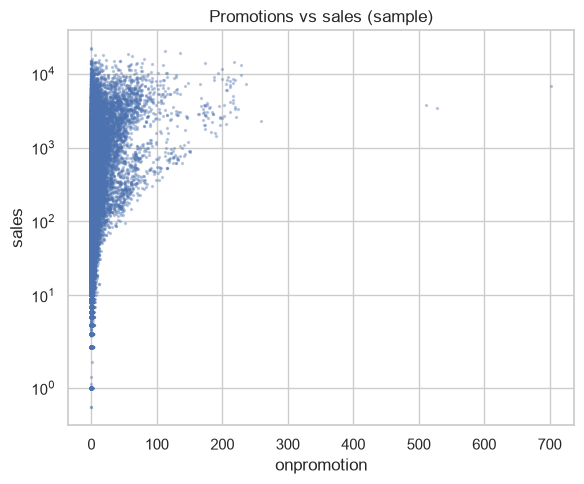

In [14]:
print("Rows with onpromotion > 0: {:.1f}%".format((train[PROMO] > 0).mean() * 100))
by_year = train.groupby(train[DATE].dt.year)[PROMO].apply(lambda s: (s > 0).mean() * 100).round(1)
print("Share of rows with a promotion, by year (%):")
print(by_year)
positive = train[train[TARGET] > 0]
sample = positive.sample(min(50_000, len(positive)), random_state=config["seed"])
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(sample[PROMO], sample[TARGET], s=2, alpha=0.3)
ax.set_xlabel("onpromotion"); ax.set_ylabel("sales"); ax.set_yscale("symlog"); ax.set_title("Promotions vs sales (sample)")
plt.tight_layout()
plt.savefig(PLOTS / "01_promo_vs_sales.png", dpi=120)
plt.show()

## 9. Valeurs extrêmes / القيم المتطرفة

In [15]:
q = train[TARGET].quantile([0.5, 0.9, 0.99, 0.999, 1.0])
print(q)
train.nlargest(10, TARGET)[[DATE, "store_nbr", PROD, TARGET, PROMO]]

0.500        11.000000
0.900       867.000000
0.990      5507.000000
0.999     12076.225548
1.000    124717.000000
Name: sales, dtype: float64


,date,store_nbr,family,sales,onpromotion
2163723,2016-05-02,2,GROCERY I,124717.000,59
2445984,2016-10-07,39,MEATS,89576.360,0
2144154,2016-04-21,20,GROCERY I,87438.516,53
2139699,2016-04-18,45,GROCERY I,76090.000,38
2153031,2016-04-26,2,GROCERY I,63434.000,30
2145045,2016-04-21,45,GROCERY I,53874.000,44
562596,2013-11-12,44,GROCERY I,46271.000,0
1257246,2014-12-08,35,GROCERY I,45361.000,3
1916586,2015-12-14,35,GROCERY I,40351.460,7
2760297,2017-04-02,9,GROCERY I,38422.625,73


## 10. Fichiers auxiliaires / الملفات المساعدة

In [16]:
stores = dl.load_stores(config)
print("stores:", stores.shape); display(stores.head())
holidays = dl.load_holidays(config)
print("holidays_events:", holidays.shape)
print(holidays["locale"].value_counts())
print("transferred = True:", int(holidays["transferred"].sum()))

stores: (54, 5)


,store_nbr,city,state,type,cluster
0,1,Quito,Pichincha,D,13
1,2,Quito,Pichincha,D,13
2,3,Quito,Pichincha,D,8
3,4,Quito,Pichincha,D,9
4,5,Santo Domingo,Santo Domingo de los Tsachilas,D,4


holidays_events: (350, 6)
locale
National    174
Local       152
Regional     24
Name: count, dtype: int64
transferred = True: 12


In [17]:
oil = dl.load_oil(config)
print("oil:", oil.shape, "| columns:", list(oil.columns))
print("Missing values:"); print(oil.isna().sum())
tx = dl.load_transactions(config)
print("\ntransactions:", tx.shape, "| columns:", list(tx.columns))
print("Missing values:"); print(tx.isna().sum())

oil: (1218, 2) | columns: ['date', 'dcoilwtico']
Missing values:
date           0
dcoilwtico    43
dtype: int64

transactions: (83488, 3) | columns: ['date', 'store_nbr', 'transactions']
Missing values:
date            0
store_nbr       0
transactions    0
dtype: int64


## 11. Conclusions / الخلاصات
À compléter après exécution avec **tes** résultats (je les commenterai avec toi) :

- Nombre de familles, plage de dates, jours manquants.
- Part de ventes à zéro et familles concernées.
- Familles à forte saisonnalité ou à promotions fréquentes.
- Valeurs extrêmes à examiner à l'Étape 4.